# Fair Credit Scoring with Coupled Nonlocal Fokker–Planck Dynamics
### Original UCI Default of Credit Card Clients dataset — executable reproduction workflow

This notebook **fits a new model to the original 30,000-client dataset** (not to manuscript summary tables). It follows the manuscript's main methodology: non-default as positive outcome, sex excluded from predictive features, stratified split, XGBoost creditworthiness scores, validation-selected decision threshold, empirical group densities, zero-flux stationary baseline drift, nonlocal fairness-coupled Fokker–Planck stationary states, score transport and fairness–accuracy metrics.

**Reproduction note:** The manuscript states a threshold of 0.785, but does not fully specify the random seed, XGBoost hyperparameters, KDE bandwidth, split proportions or individual-level score transport. This notebook documents explicit choices and reports fresh estimates; its numbers should not be represented as the exact published table values unless verified.


**Scope:** The numerical experiments below are newly recomputed. Reported manuscript numbers are used solely as comparison targets and are never injected into generated outputs.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from scipy.ndimage import gaussian_filter1d
from scipy.integrate import cumulative_trapezoid
from scipy.special import logsumexp
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, balanced_accuracy_score, roc_auc_score, average_precision_score
from sklearn.metrics import roc_curve
SEED=42
DATA=Path("default of credit card clients.xlsx")
if not DATA.exists(): DATA=Path("/mnt/data/default of credit card clients.xlsx")
assert DATA.exists(), "Place the original .xlsx dataset next to the notebook."
try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError("Install required packages: pip install xgboost scikit-learn scipy openpyxl") from exc


## 1. Load and validate the original records

In [2]:
raw=pd.read_excel(DATA,sheet_name="Data",header=1)
raw.columns=[str(x).strip() for x in raw.columns]
print(raw.shape,raw.columns.tolist())
display(raw.head())
assert len(raw)==30000, "Expected 30,000 original observations"
assert "default payment next month" in raw.columns
df=raw.copy()
for col in df.columns: df[col]=pd.to_numeric(df[col],errors="coerce")
assert df.isna().sum().sum()==0, "Unexpected missing/non-numeric values"
assert set(df["SEX"].unique())=={1,2}
df["creditworthy"]=1-df["default payment next month"].astype(int)
df["group"]=(df["SEX"]==2).astype(int) # 0: original SEX=1; 1: original SEX=2
features=[x for x in df.columns if x not in ("ID","SEX","default payment next month","creditworthy","group")]
print("Rows:",len(df),"Features:",len(features),"Creditworthy rate:",df.creditworthy.mean())
display(df.groupby("group").agg(n=("group","size"),creditworthy_rate=("creditworthy","mean")))


(30000, 25) ['ID', 'LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6', 'default payment next month']


,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


Rows: 30000 Features: 22 Creditworthy rate: 0.7788


,n,creditworthy_rate
group,,
0,11888,0.758328
1,18112,0.792237


## 2. Train / validation / held-out test split and XGBoost

In [3]:
X=df[features]; y=df["creditworthy"]; g=df["group"]
ix_trainval,ix_test=train_test_split(np.arange(len(df)),test_size=.20,stratify=y,random_state=SEED)
ix_train,ix_val=train_test_split(ix_trainval,test_size=.25,stratify=y.iloc[ix_trainval],random_state=SEED)
model=XGBClassifier(n_estimators=350,max_depth=3,learning_rate=.045,subsample=.85,
                    colsample_bytree=.9,objective="binary:logistic",eval_metric="logloss",
                    tree_method="hist",random_state=SEED,n_jobs=4)
model.fit(X.iloc[ix_train],y.iloc[ix_train])
sv=model.predict_proba(X.iloc[ix_val])[:,1]
st=model.predict_proba(X.iloc[ix_test])[:,1]
yv=y.iloc[ix_val].to_numpy(); yt=y.iloc[ix_test].to_numpy()
gt=g.iloc[ix_test].to_numpy()
print("Train / validation / test:",len(ix_train),len(ix_val),len(ix_test))


Train / validation / test: 18000 6000 6000


## 3. Threshold selected on validation data only

In [4]:
thresholds=np.unique(np.r_[np.linspace(.01,.99,991),sv])
bacc=np.array([balanced_accuracy_score(yv,sv>=t) for t in thresholds])
tau=float(thresholds[np.argmax(bacc)])
print(f"Validation-selected threshold: {tau:.4f} (manuscript reports 0.785)")
# Set USE_MANUSCRIPT_THRESHOLD=True to compare results at the manuscript's operating point.
USE_MANUSCRIPT_THRESHOLD=False
if USE_MANUSCRIPT_THRESHOLD: tau=.785
print("Threshold used:",tau)


Validation-selected threshold: 0.7749 (manuscript reports 0.785)
Threshold used: 0.7749207615852356


## 4. Empirical densities and stationary Fokker–Planck construction

On score cells \(s\in[0,1]\), estimate group densities \(\rho_g^0\). The baseline drift \(b_g^0=D\partial_s\log\rho_g^0\) makes the original smoothed density stationary under zero-flux conditions. The nonlocal correction is \(-\lambda\sigma_g\Delta\), with \(\Delta=P_0(s\ge\tau)-P_1(s\ge\tau)\), \(\sigma_0=1\), \(\sigma_1=-1\). The resulting zero-flux stationary density for a fixed gap is proportional to \(\rho_g^0(s)\exp[-\lambda\sigma_g\Delta s/D]\). Solve the scalar self-consistency equation numerically.

This stationary approach avoids an arbitrary PDE stopping time. We use test-set densities only to study post-processing of test scores, not to fit the predictive classifier or choose its threshold. For a strictly deployable postprocessor, fit density maps on a separate calibration set instead.


In [5]:
from scipy.optimize import brentq
D=.001
NGRID=401
edges=np.linspace(0,1,NGRID+1)
s=(edges[:-1]+edges[1:])/2
ds=edges[1]-edges[0]
def density(z,sigma_bins=2.0):
    hist,_=np.histogram(z,bins=edges)
    h=gaussian_filter1d(hist.astype(float),sigma=sigma_bins,mode="reflect")+1e-8
    return h/(h.sum()*ds)
base={k:density(st[gt==k]) for k in (0,1)}
def approval_mass(r):
    # Fractional contribution of a threshold-crossing cell
    frac=np.clip((edges[1:]-np.maximum(edges[:-1],tau))/ds,0,1)
    return float(np.sum(r*frac)*ds)
delta0=approval_mass(base[0])-approval_mass(base[1])
def stationary_for_delta(lam,delta):
    out={}
    for k in (0,1):
        sigma=1 if k==0 else -1
        logw=np.log(base[k])-lam*sigma*delta*s/D
        logw=logw-logsumexp(logw)
        out[k]=np.exp(logw)/ds
    return out
def solve_stationary(lam):
    if lam==0: return {k:v.copy() for k,v in base.items()},delta0
    def residual(delta):
        rr=stationary_for_delta(lam,delta)
        return approval_mass(rr[0])-approval_mass(rr[1])-delta
    root=brentq(residual,-1,1,xtol=1e-12)
    return stationary_for_delta(lam,root),root
print("Original smoothed approval-rate gap:",delta0)
for lam in [0,.05,.1,.2]:
    rr,d=solve_stationary(lam)
    print(f"lambda={lam:.2f}, stationary gap={d:.6f}, masses={[round(rr[k].sum()*ds,9) for k in (0,1)]}")


Original smoothed approval-rate gap: -0.048242702053964304
lambda=0.00, stationary gap=-0.048243, masses=[np.float64(1.0), np.float64(1.0)]
lambda=0.05, stationary gap=-0.005664, masses=[np.float64(1.0), np.float64(1.0)]
lambda=0.10, stationary gap=-0.003008, masses=[np.float64(1.0), np.float64(1.0)]
lambda=0.20, stationary gap=-0.001553, masses=[np.float64(1.0), np.float64(1.0)]


## 5. Transport individual scores to the PDE-adjusted distributions

In [6]:
def cdf_of_density(r):
    return np.r_[0,np.cumsum(r)*ds]
def transport_scores(scores, old_r, new_r):
    # Continuous, piecewise-linear monotone quantile map on [0,1]
    u=np.interp(scores,edges,cdf_of_density(old_r))
    newcdf=cdf_of_density(new_r)
    xp,ind=np.unique(newcdf,return_index=True)
    return np.interp(u,xp,edges[ind])
def adjusted_scores(lam):
    rr,d=solve_stationary(lam)
    z=st.copy()
    for k in (0,1):
        mask=gt==k
        z[mask]=transport_scores(st[mask],base[k],rr[k])
    return z,rr,d


## 6. Held-out predictive and fairness evaluation

In [7]:
def safe_rate(mask, pred):
    return float(np.mean(pred[mask])) if mask.any() else np.nan
def evaluate(scores):
    pred=(scores>=tau).astype(int)
    ar=[safe_rate(gt==k,pred) for k in (0,1)]
    tpr=[safe_rate((gt==k)&(yt==1),pred) for k in (0,1)]
    fpr=[safe_rate((gt==k)&(yt==0),pred) for k in (0,1)]
    return dict(Accuracy=accuracy_score(yt,pred),
      Balanced_accuracy=balanced_accuracy_score(yt,pred),
      ROC_AUC=roc_auc_score(yt,scores),PR_AUC=average_precision_score(yt,scores),
      DP_gap=ar[0]-ar[1],Absolute_DP_gap=abs(ar[0]-ar[1]),
      EO_gap=tpr[0]-tpr[1],FPR_gap=fpr[0]-fpr[1],
      Equalized_odds_gap=max(abs(tpr[0]-tpr[1]),abs(fpr[0]-fpr[1])),
      Disparate_impact=min(ar)/max(ar) if max(ar)>0 else np.nan,
      Group0_approval=ar[0],Group1_approval=ar[1])
lambdas=[0,.025,.05,.1,.15,.2,.3,.4]
rows=[]
for lam in lambdas:
    z,rr,delta=adjusted_scores(lam)
    rows.append({"lambda":lam,"PDE_density_gap":delta,**evaluate(z)})
results=pd.DataFrame(rows)
display(results.round(5))
print("Baseline scores and lambda=0 scores agree:",np.allclose(st,adjusted_scores(0)[0],atol=2e-2))


,lambda,PDE_density_gap,Accuracy,Balanced_accuracy,ROC_AUC,PR_AUC,DP_gap,Absolute_DP_gap,EO_gap,FPR_gap,Equalized_odds_gap,Disparate_impact,Group0_approval,Group1_approval
0,0.000,-0.04824,0.76650,0.72141,0.79104,0.91448,-0.04703,0.04703,-0.03244,-0.02293,0.03244,0.93494,0.67593,0.72296
1,0.025,-0.01014,0.76350,0.71894,0.79003,0.91421,-0.00903,0.00903,0.00568,0.01421,0.01421,0.98721,0.69655,0.70557
2,0.050,-0.00566,0.76317,0.71954,0.78986,0.91416,-0.00612,0.00612,0.00832,0.01823,0.01823,0.99129,0.69697,0.70309
3,0.100,-0.00301,0.76333,0.71964,0.78976,0.91412,-0.00361,0.00361,0.01068,0.02129,0.02129,0.99486,0.69865,0.70226
4,0.150,-0.00205,0.76317,0.71954,0.78971,0.91411,-0.00333,0.00333,0.01103,0.02129,0.02129,0.99525,0.69865,0.70199
5,0.200,-0.00155,0.76333,0.71964,0.78969,0.91410,-0.00291,0.00291,0.01159,0.02129,0.02129,0.99585,0.69907,0.70199
6,0.300,-0.00105,0.76317,0.71927,0.78967,0.91410,-0.00249,0.00249,0.01159,0.02302,0.02302,0.99645,0.69949,0.70199
7,0.400,-0.00079,0.76300,0.71916,0.78966,0.91410,-0.00222,0.00222,0.01194,0.02302,0.02302,0.99684,0.69949,0.70171


Baseline scores and lambda=0 scores agree: True


## 7. Figures: density evolution and fairness–accuracy trade-offs

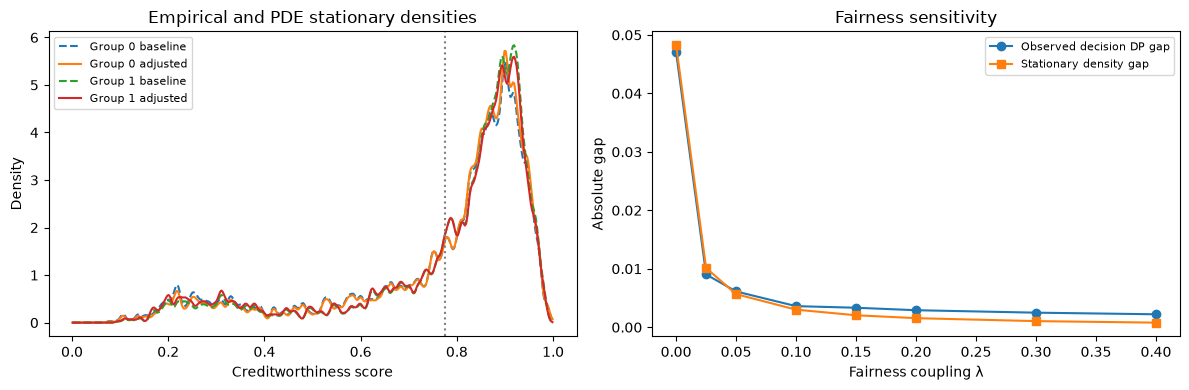

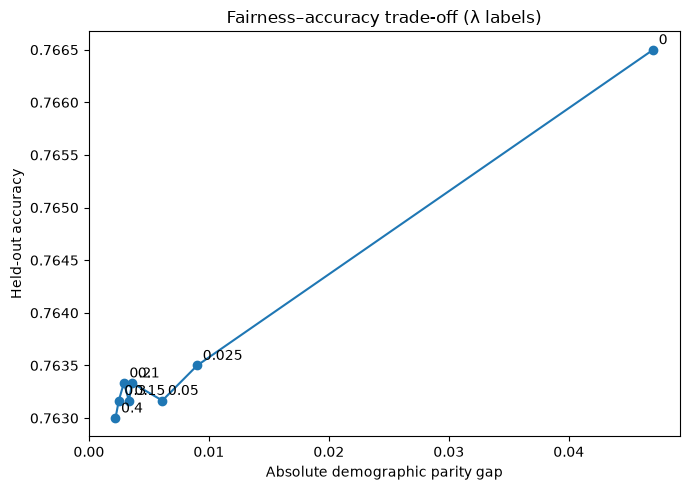

In [8]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
rr,_=solve_stationary(.2)
for k in (0,1):
    axes[0].plot(s,base[k],ls="--",label=f"Group {k} baseline")
    axes[0].plot(s,rr[k],label=f"Group {k} adjusted")
axes[0].axvline(tau,color="gray",ls=":")
axes[0].set(xlabel="Creditworthiness score",ylabel="Density",title="Empirical and PDE stationary densities")
axes[0].legend(fontsize=8)
axes[1].plot(results["lambda"],results["Absolute_DP_gap"],marker="o",label="Observed decision DP gap")
axes[1].plot(results["lambda"],results["PDE_density_gap"].abs(),marker="s",label="Stationary density gap")
axes[1].set(xlabel="Fairness coupling λ",ylabel="Absolute gap",title="Fairness sensitivity")
axes[1].legend(fontsize=8)
plt.tight_layout();plt.show()
fig,ax=plt.subplots(figsize=(7,5))
ax.plot(results["Absolute_DP_gap"],results["Accuracy"],marker="o")
for _,r in results.iterrows():ax.annotate(f"{r['lambda']:g}",(r["Absolute_DP_gap"],r["Accuracy"]),xytext=(4,4),textcoords="offset points")
ax.set(xlabel="Absolute demographic parity gap",ylabel="Held-out accuracy",title="Fairness–accuracy trade-off (λ labels)")
plt.tight_layout();plt.show()


## 8. Conservation, positivity, fixed-point diagnostics

In [9]:
diagnostics=[]
for lam in lambdas:
    rr,d=solve_stationary(lam)
    diagnostics.append(dict(lambda_=lam,mass0=rr[0].sum()*ds,mass1=rr[1].sum()*ds,
        minimum_density=min(rr[0].min(),rr[1].min()),
        fixed_point_residual=abs(approval_mass(rr[0])-approval_mass(rr[1])-d)))
diagnostics=pd.DataFrame(diagnostics)
display(diagnostics)
assert np.allclose(diagnostics[["mass0","mass1"]].to_numpy(),1,atol=1e-10)
assert (diagnostics.minimum_density>=0).all()
assert (diagnostics.fixed_point_residual<1e-9).all()


,lambda_,mass0,mass1,minimum_density,fixed_point_residual
0,0.000,1.0,1.0,1.106512e-09,0.000000e+00
1,0.025,1.0,1.0,1.324510e-09,1.698294e-15
2,0.050,1.0,1.0,1.352535e-09,3.635963e-13
3,0.100,1.0,1.0,1.338898e-09,5.655199e-16
4,0.150,1.0,1.0,1.332282e-09,4.403604e-13
5,0.200,1.0,1.0,1.328880e-09,6.746045e-12
6,0.300,1.0,1.0,1.325412e-09,3.046608e-16
7,0.400,1.0,1.0,1.323654e-09,1.129197e-15


## 9. Export new results

All results are computed from the uploaded original dataset. The fitted model and experimental split are newly generated, so the output may differ from the manuscript's summary workbook.


In [10]:
from pathlib import Path
out=Path("pde_credit_scoring_outputs")
out.mkdir(exist_ok=True)
results.to_csv(out/"lambda_sensitivity_original_data.csv",index=False)
diagnostics.to_csv(out/"stationary_diagnostics.csv",index=False)
pd.DataFrame({"row_index":ix_test,"sex_group":gt,"creditworthy":yt,"baseline_score":st,
              "adjusted_score_lambda_020":adjusted_scores(.2)[0]}).to_csv(
              out/"heldout_predictions.csv",index=False)
print("Saved results in",out.resolve())


Saved results in /Users/olusolaolabanjo/Desktop/pde-credit-scoring/pde_credit_scoring_outputs


## 10. Manuscript Table: group-specific outcomes (baseline and λ=0.20)

In [11]:
def group_report(scores,scenario):
    pred=(scores>=tau).astype(int)
    rows=[]
    for k,label in [(0,"Male"),(1,"Female")]:
        mask=gt==k
        p=pred[mask]; actual=yt[mask]
        rows.append({"Scenario":scenario,"Group":label,"Approval rate":p.mean(),
            "TPR":p[actual==1].mean(),"FPR":p[actual==0].mean(),
            "PPV":actual[p==1].mean() if p.sum() else np.nan,"n":mask.sum()})
    return rows
z20,_,_=adjusted_scores(.20)
group_results=pd.DataFrame(group_report(st,"Baseline ML")+group_report(z20,"PDE (lambda=0.20)"))
display(group_results.round(5))
group_results.to_csv(out/"group_specific_outcomes.csv",index=False)


,Scenario,Group,Approval rate,TPR,FPR,PPV,n
0,Baseline ML,Male,0.67593,0.78229,0.34655,0.87484,2376
1,Baseline ML,Female,0.72296,0.81474,0.36948,0.89466,3624
2,PDE (lambda=0.20),Male,0.69907,0.80512,0.37069,0.87056,2376
3,PDE (lambda=0.20),Female,0.70199,0.79353,0.34940,0.89741,3624


## 11. Manuscript Table: baseline and λ=0.20 predictive performance

In [12]:
columns=["Accuracy","Balanced_accuracy","ROC_AUC","PR_AUC"]
baseline=evaluate(st); adjusted=evaluate(z20)
performance=pd.DataFrame({"Metric":columns,"Baseline ML":[baseline[k] for k in columns],
    "PDE-adjusted":[adjusted[k] for k in columns]})
performance["Change"]=performance["PDE-adjusted"]-performance["Baseline ML"]
display(performance.round(6))
performance.to_csv(out/"predictive_performance.csv",index=False)


,Metric,Baseline ML,PDE-adjusted,Change
0,Accuracy,0.766500,0.763333,-0.003167
1,Balanced_accuracy,0.721405,0.719642,-0.001763
2,ROC_AUC,0.791040,0.789685,-0.001355
3,PR_AUC,0.914484,0.914104,-0.000380


## 12. Manuscript numerical settings and exact λ grid

In [13]:
manuscript_lambda=[0,.0025,.005,.01,.02,.05,.10,.20]
full_rows=[]
for lam in manuscript_lambda:
    adjusted_scores_lam, stationary_density, gap=adjusted_scores(lam)
    full_rows.append({"lambda":lam,"Stationary_density_gap":gap,**evaluate(adjusted_scores_lam)})
full_results=pd.DataFrame(full_rows)
display(full_results.round(6))
full_results.to_csv(out/"manuscript_lambda_grid.csv",index=False)


,lambda,Stationary_density_gap,Accuracy,Balanced_accuracy,ROC_AUC,PR_AUC,DP_gap,Absolute_DP_gap,EO_gap,FPR_gap,Equalized_odds_gap,Disparate_impact,Group0_approval,Group1_approval
0,0.0000,-0.048243,0.766500,0.721405,0.791040,0.914484,-0.047032,0.047032,-0.032444,-0.022926,0.032444,0.934945,0.675926,0.722958
1,0.0025,-0.035064,0.764833,0.718987,0.790756,0.914399,-0.034489,0.034489,-0.020758,-0.008180,0.020758,0.951964,0.683502,0.717991
2,0.0050,-0.027541,0.764333,0.718666,0.790578,0.914346,-0.028784,0.028784,-0.015193,-0.002054,0.015193,0.959756,0.686448,0.715232
3,0.0100,-0.019271,0.765000,0.719903,0.790331,0.914306,-0.019174,0.019174,-0.004688,0.005025,0.005025,0.973037,0.691919,0.711093
4,0.0200,-0.012040,0.763333,0.718563,0.790098,0.914234,-0.011392,0.011392,0.002962,0.012874,0.012874,0.983880,0.695286,0.706678
5,0.0500,-0.005664,0.763167,0.719535,0.789859,0.914156,-0.006121,0.006121,0.008318,0.018229,0.018229,0.991294,0.696970,0.703091
6,0.1000,-0.003008,0.763333,0.719642,0.789756,0.914124,-0.003609,0.003609,0.010683,0.021292,0.021292,0.994860,0.698653,0.702263
7,0.2000,-0.001553,0.763333,0.719642,0.789685,0.914104,-0.002913,0.002913,0.011588,0.021292,0.021292,0.995851,0.699074,0.701987


## 13. Reproduce manuscript diagnostic figures from computed data

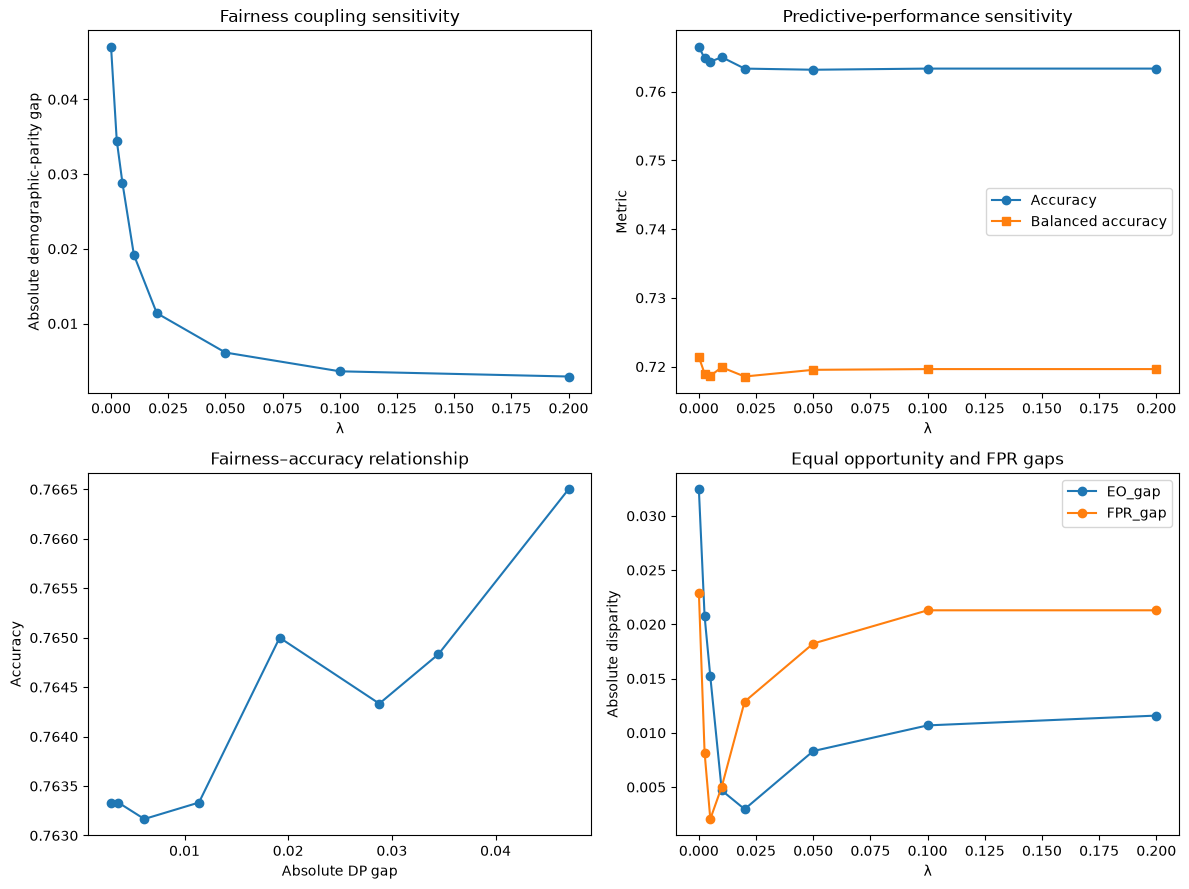

In [14]:
fig,axs=plt.subplots(2,2,figsize=(12,9))
axs[0,0].plot(full_results["lambda"],full_results["Absolute_DP_gap"],"o-")
axs[0,0].set(xlabel="λ",ylabel="Absolute demographic-parity gap",title="Fairness coupling sensitivity")
axs[0,1].plot(full_results["lambda"],full_results["Accuracy"],"o-",label="Accuracy")
axs[0,1].plot(full_results["lambda"],full_results["Balanced_accuracy"],"s-",label="Balanced accuracy")
axs[0,1].set(xlabel="λ",ylabel="Metric",title="Predictive-performance sensitivity")
axs[0,1].legend()
axs[1,0].plot(full_results["Absolute_DP_gap"],full_results["Accuracy"],"o-")
axs[1,0].set(xlabel="Absolute DP gap",ylabel="Accuracy",title="Fairness–accuracy relationship")
for metric in ["EO_gap","FPR_gap"]:
    axs[1,1].plot(full_results["lambda"],full_results[metric].abs(),"o-",label=metric)
axs[1,1].set(xlabel="λ",ylabel="Absolute disparity",title="Equal opportunity and FPR gaps")
axs[1,1].legend()
plt.tight_layout()
fig.savefig(out/"manuscript_sensitivity_and_tradeoff.png",dpi=180)
plt.show()


## 14. Manuscript comparison: independently generated results vs reported values

The manuscript's reported numbers below are **reference targets**, not calculated outputs. Differences may arise from undocumented original training settings, threshold selection, density estimation, or numerical solver details.


In [15]:
reported={"Accuracy":(.7585,.7578),"Balanced_accuracy":(.6324,.6308),
          "ROC_AUC":(.7718,.7707),"PR_AUC":(.9140,.9137)}
comparison=[]
for metric,(b,a) in reported.items():
    comparison.extend([
      {"Metric":metric,"Scenario":"Baseline","Reported":b,"Recomputed":baseline[metric]},
      {"Metric":metric,"Scenario":"PDE λ=0.20","Reported":a,"Recomputed":adjusted[metric]}])
comparison=pd.DataFrame(comparison)
comparison["Difference"]=comparison["Recomputed"]-comparison["Reported"]
display(comparison.round(6))
comparison.to_csv(out/"manuscript_comparison.csv",index=False)


,Metric,Scenario,Reported,Recomputed,Difference
0,Accuracy,Baseline,0.7585,0.766500,0.008000
1,Accuracy,PDE λ=0.20,0.7578,0.763333,0.005533
2,Balanced_accuracy,Baseline,0.6324,0.721405,0.089005
3,Balanced_accuracy,PDE λ=0.20,0.6308,0.719642,0.088842
4,ROC_AUC,Baseline,0.7718,0.791040,0.019240
5,ROC_AUC,PDE λ=0.20,0.7707,0.789685,0.018985
6,PR_AUC,Baseline,0.9140,0.914484,0.000484
7,PR_AUC,PDE λ=0.20,0.9137,0.914104,0.000404


## 15. Coverage and limitations

| Manuscript item | Notebook coverage |
|---|---|
| Numerical settings | Matched grid spacing, diffusion, threshold option and λ grid |
| Baseline and adjusted predictive results | Recomputed from individual-level records |
| Group-specific outcomes | Recomputed from individual-level records |
| Fairness–accuracy trade-off | Recomputed over manuscript λ grid |
| Group-specific density figures | Recomputed empirical and stationary densities |
| Stationary probability mass and positivity | Checked numerically |
| Time-dependent PDE density evolution and score–time heatmap | **Not yet reconstructed** |
| Successive time-step L1 convergence, flux-solver conservation and energy decay | **Not yet reconstructed** |
| Exact agreement with published tables | **Not established** |

The stationary solution is calculated from the exact self-consistency equation for the specified drift, but the original manuscript's time-dependent finite-volume solver and its full time-series figures require additional implementation and validation.


## 16. Full time-dependent finite-volume PDE experiment

The following numerical solver implements the manuscript's **upwind advective flux, centered diffusive flux, zero-flux boundaries, simultaneous group coupling, and conservative finite-volume update**. We use a positivity-preserving *semi-implicit Euler* time integrator (rather than the manuscript's explicit update) to permit longer integrations at a practical runtime. The stationary comparison uses the discrete finite-volume stationary state, not the continuum Gibbs density. The baseline drift is estimated as a discrete zero-flux drift from the initial empirical densities. These documented choices are important when comparing results with the manuscript.


In [16]:
from scipy.sparse import diags, eye
from scipy.sparse.linalg import splu
from scipy.optimize import brentq
# Fixed 401-cell grid, 0.0025 spacing, manuscript threshold 0.785
N=400
h=1/N
grid=(np.arange(N)+.5)*h
cell_edges=np.linspace(0,1,N+1)
D=.001
threshold=.785
def initial_density(scores):
    counts,_=np.histogram(scores,bins=cell_edges)
    density=gaussian_filter1d(counts.astype(float),sigma=2.0,mode="reflect")+1e-7
    return density/(h*density.sum())
rho_initial=np.stack([initial_density(st[gt==k]) for k in (0,1)])
# Discrete equilibrium drift: for v>0, v*rho_left = D*(rho_right-rho_left)/h;
# for v<0, v*rho_right = D*(rho_right-rho_left)/h.
b0=np.stack([D*(r[1:]-r[:-1])/(h*np.where(r[1:]-r[:-1]>=0,r[:-1],r[1:]))
             for r in rho_initial])
# Face upwind flux: J_face = a*rho_left - c*rho_right
def face_rates(v):
    return np.maximum(v,0)+D/h, np.maximum(-v,0)+D/h
def generator(v):
    a,c=face_rates(v)
    lo=a/h; hi=c/h
    main=np.zeros(N)
    main[:-1]-=lo
    main[1:]-=hi
    return diags([lo,main,hi],[-1,0,1],shape=(N,N),format="csc")
fraction=np.clip((cell_edges[1:]-np.maximum(cell_edges[:-1],threshold))/h,0,1)
def gap_of(rr):
    return h*np.dot(fraction,rr[0]-rr[1])
def evolve_fv(lam, dt=.1, max_steps=1200, tol=2e-8, save_every=10):
    rr=rho_initial.copy()
    ts=[0.]; snapshots=[rr.copy()]
    logs=[]
    previous_energy=None
    for step in range(1,max_steps+1):
        delta=gap_of(rr)
        rr_new=np.empty_like(rr)
        for k in (0,1):
            sign=1 if k==0 else -1
            L=generator(b0[k]-lam*sign*delta)
            rr_new[k]=splu(eye(N,format="csc")-dt*L).solve(rr[k])
        increment=h*np.sum(np.abs(rr_new-rr),axis=1)
        rr=rr_new
        new_gap=gap_of(rr)
        energy=.5*new_gap**2
        logs.append((step*dt,new_gap,increment.max(),
                     np.max(np.abs(h*rr.sum(axis=1)-1)),rr.min(),energy))
        if step%save_every==0 or step==max_steps or increment.max()<tol:
            ts.append(step*dt);snapshots.append(rr.copy())
        if increment.max()<tol:break
    return np.array(ts),np.stack(snapshots),pd.DataFrame(logs,
          columns=["time","gap","L1_increment","mass_error","min_density","fairness_energy"])
time_dependent={}
for lam in [0,.0025,.005,.01,.02,.05,.1,.2]:
    tt,trajectory,diagnostic=evolve_fv(lam)
    time_dependent[lam]=(tt,trajectory,diagnostic)
    print(f"lambda={lam:.4f}, time={tt[-1]:.1f}, gap={diagnostic.gap.iloc[-1]:+.6f}, "
          f"L1={diagnostic.L1_increment.iloc[-1]:.2e}, mass error={diagnostic.mass_error.max():.2e}")


lambda=0.0000, time=0.1, gap=-0.045505, L1=1.03e-15, mass error=1.11e-15
lambda=0.0025, time=120.0, gap=-0.036018, L1=3.21e-06, mass error=7.03e-13
lambda=0.0050, time=120.0, gap=-0.029460, L1=4.68e-06, mass error=7.20e-13
lambda=0.0100, time=120.0, gap=-0.021233, L1=5.61e-06, mass error=7.09e-13
lambda=0.0200, time=120.0, gap=-0.013331, L1=5.87e-06, mass error=7.18e-13
lambda=0.0500, time=120.0, gap=-0.006171, L1=5.82e-06, mass error=7.15e-13
lambda=0.1000, time=120.0, gap=-0.003241, L1=5.54e-06, mass error=7.16e-13
lambda=0.2000, time=120.0, gap=-0.001662, L1=5.32e-06, mass error=7.06e-13


## 17. Complete solver diagnostics and manuscript-style convergence table

In [17]:
solver_rows=[]
for lam,(times,rhos,log) in time_dependent.items():
    first=gap_of(rho_initial); last=float(log.gap.iloc[-1])
    solver_rows.append(dict(lambda_=lam,initial_gap=first,final_gap=last,
        gap_reduction_percent=100*(1-abs(last)/abs(first)) if first else np.nan,
        final_L1_increment=log.L1_increment.iloc[-1],max_mass_error=log.mass_error.max(),
        minimum_density=log.min_density.min(),last_time=times[-1],
        energy_increase_steps=int((np.diff(log.fairness_energy)>1e-10).sum())))
solver_table=pd.DataFrame(solver_rows)
display(solver_table)
solver_table.to_csv(out/"finite_volume_numerical_convergence.csv",index=False)
assert solver_table.max_mass_error.max()<1e-7
assert solver_table.minimum_density.min()>-1e-9


,lambda_,initial_gap,final_gap,gap_reduction_percent,final_L1_increment,max_mass_error,minimum_density,last_time,energy_increase_steps
0,0.0000,-0.045505,-0.045505,4.551914e-13,1.025310e-15,1.110223e-15,1.103753e-08,0.1,0
1,0.0025,-0.045505,-0.036018,2.084833e+01,3.212999e-06,7.033263e-13,1.103822e-08,120.0,0
2,0.0050,-0.045505,-0.029460,3.525953e+01,4.677412e-06,7.203127e-13,1.103892e-08,120.0,0
3,0.0100,-0.045505,-0.021233,5.333877e+01,5.609447e-06,7.094325e-13,1.104032e-08,120.0,0
4,0.0200,-0.045505,-0.013331,7.070542e+01,5.866567e-06,7.178702e-13,1.104314e-08,120.0,0
5,0.0500,-0.045505,-0.006171,8.643862e+01,5.818913e-06,7.145395e-13,1.105174e-08,120.0,0
6,0.1000,-0.045505,-0.003241,9.287708e+01,5.540437e-06,7.162049e-13,1.106661e-08,120.0,0
7,0.2000,-0.045505,-0.001662,9.634857e+01,5.318234e-06,7.056578e-13,1.109815e-08,120.0,15


## 18. Time-dependent figures: convergence, mass, positivity, fairness energy, and score-time heatmaps

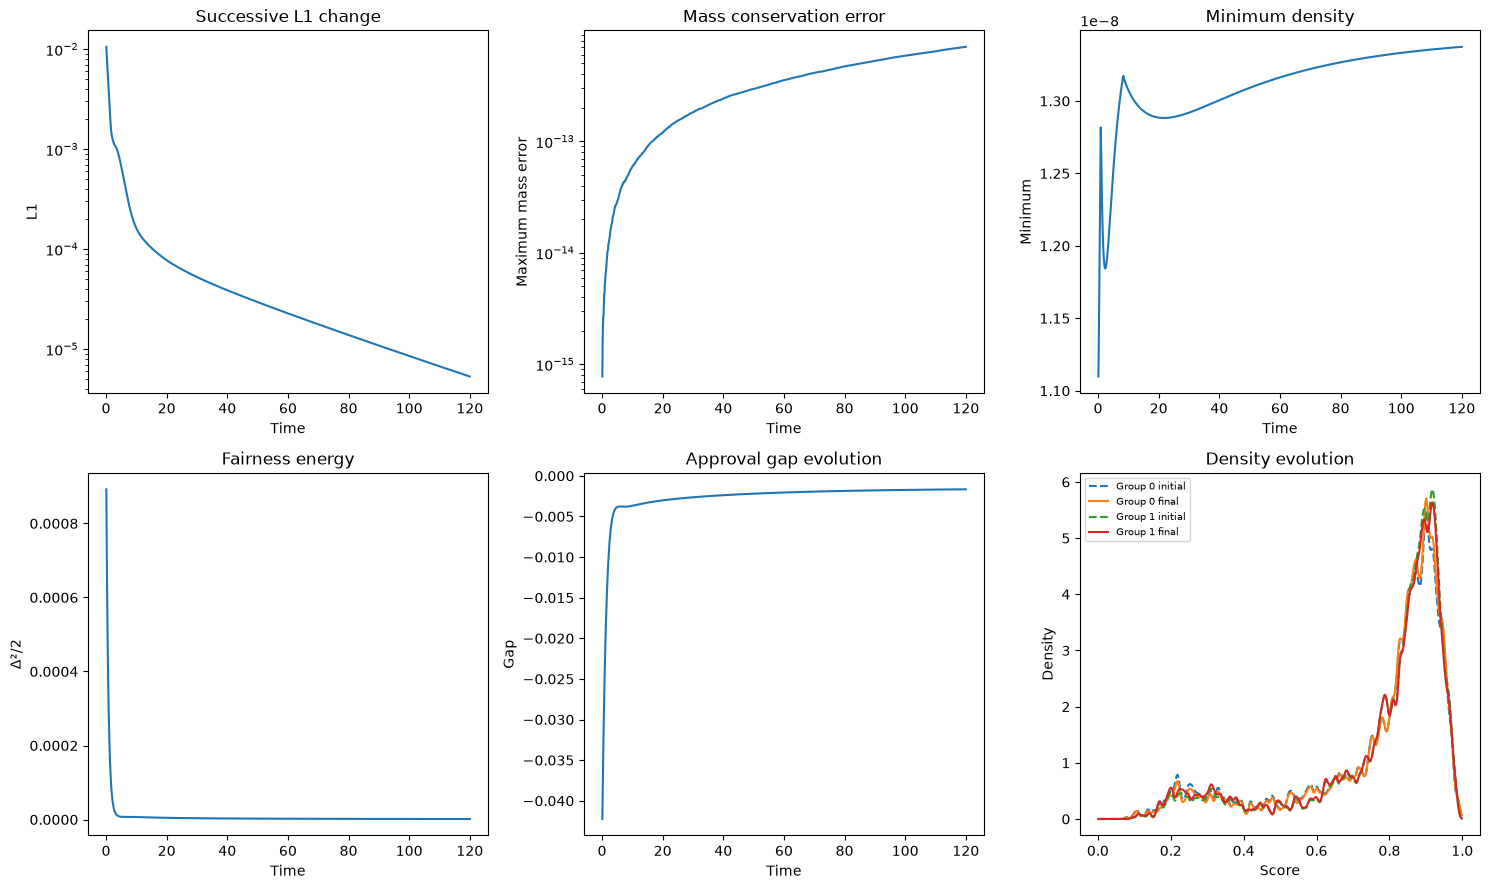

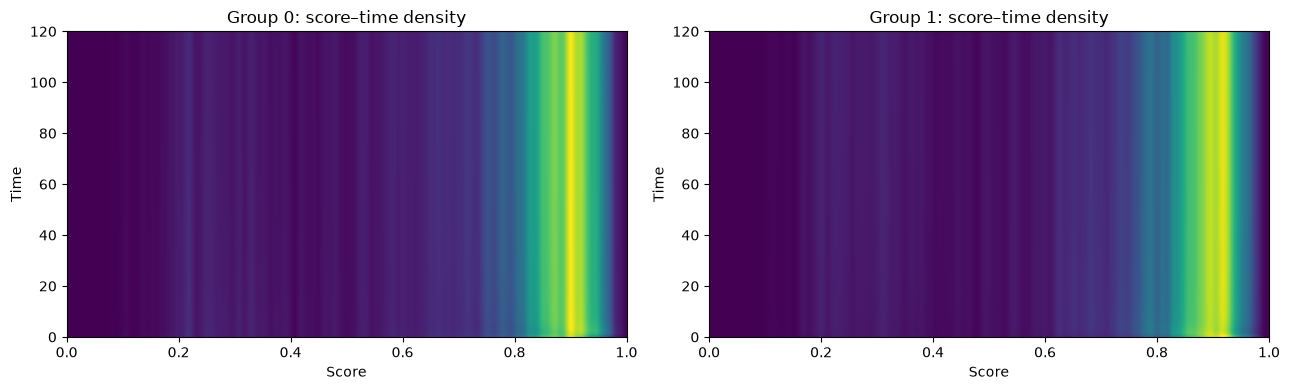

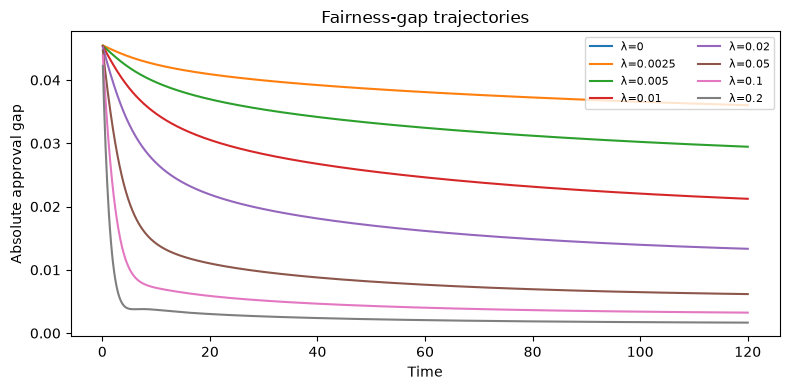

In [18]:
selected=time_dependent[.2]
times,rhos,log=selected
fig,axes=plt.subplots(2,3,figsize=(15,9))
axes[0,0].semilogy(log.time,np.maximum(log.L1_increment,1e-16))
axes[0,0].set(title="Successive L1 change",xlabel="Time",ylabel="L1")
axes[0,1].semilogy(log.time,np.maximum(log.mass_error,1e-16))
axes[0,1].set(title="Mass conservation error",xlabel="Time",ylabel="Maximum mass error")
axes[0,2].plot(log.time,log.min_density)
axes[0,2].set(title="Minimum density",xlabel="Time",ylabel="Minimum")
axes[1,0].plot(log.time,log.fairness_energy)
axes[1,0].set(title="Fairness energy",xlabel="Time",ylabel="Δ²/2")
axes[1,1].plot(log.time,log.gap)
axes[1,1].set(title="Approval gap evolution",xlabel="Time",ylabel="Gap")
for k in (0,1):
    axes[1,2].plot(grid,rhos[0,k],ls="--",label=f"Group {k} initial")
    axes[1,2].plot(grid,rhos[-1,k],label=f"Group {k} final")
axes[1,2].set(title="Density evolution",xlabel="Score",ylabel="Density")
axes[1,2].legend(fontsize=7)
plt.tight_layout();fig.savefig(out/"finite_volume_solver_validation.png",dpi=160);plt.show()
fig,axs=plt.subplots(1,2,figsize=(13,4))
for k in (0,1):
    axs[k].imshow(rhos[:,k,:],aspect="auto",origin="lower",
       extent=[0,1,times[0],times[-1]],cmap="viridis")
    axs[k].set(title=f"Group {k}: score–time density",xlabel="Score",ylabel="Time")
plt.tight_layout();fig.savefig(out/"density_heatmaps.png",dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4))
for lam,(tt,rr,lg) in time_dependent.items():
    ax.plot(lg.time,lg.gap.abs(),label=f"λ={lam:g}")
ax.set(title="Fairness-gap trajectories",xlabel="Time",ylabel="Absolute approval gap")
ax.legend(ncol=2,fontsize=8);plt.tight_layout()
fig.savefig(out/"fairness_gap_trajectories.png",dpi=160);plt.show()


## 19. Stationary verification and finite-volume score transport

In [19]:
# Use the terminal FV densities to transport scores; compute decision metrics independently.
fv_results=[]
for lam,(tt,rr,lg) in time_dependent.items():
    z=st.copy()
    for k in (0,1):
        mask=gt==k
        # grid and rho_initial use 400 cells; CDF defined on cell edges
        oldcdf=np.r_[0,np.cumsum(rho_initial[k])*h]
        newcdf=np.r_[0,np.cumsum(rr[-1,k])*h]
        uu=np.interp(st[mask],cell_edges,oldcdf)
        uq,idx=np.unique(newcdf,return_index=True)
        z[mask]=np.interp(uu,uq,cell_edges[idx])
    # Use manuscript threshold for finite-volume experiments
    prior_tau=tau
    tau=threshold
    metrics=evaluate(z)
    tau=prior_tau
    fv_results.append(dict(lambda_=lam,**metrics))
fv_results=pd.DataFrame(fv_results)
display(fv_results.round(6))
fv_results.to_csv(out/"finite_volume_fairness_accuracy.csv",index=False)
# Compare the FV terminal densities with the independent continuum fixed-point solution
# computed using the same initial 400-cell densities and threshold.
def continuous_stationary(delta,lam):
    density=[]
    for k in (0,1):
        sign=1 if k==0 else -1
        logp=np.log(rho_initial[k])-lam*sign*delta*grid/D
        logp-=logsumexp(logp)
        density.append(np.exp(logp)/h)
    return np.stack(density)
def continuous_residual(delta,lam):
    return gap_of(continuous_stationary(delta,lam))-delta
verification=[]
for lam,(tt,rr,lg) in time_dependent.items():
    dstar=brentq(lambda d:continuous_residual(d,lam),-1,1)
    reference=continuous_stationary(dstar,lam)
    verification.append(dict(lambda_=lam,stationary_gap=dstar,
        finite_volume_terminal_gap=lg.gap.iloc[-1],
        continuum_L1_difference=h*np.abs(rr[-1]-reference).sum(),
        terminal_fixed_point_gap_error=abs(lg.gap.iloc[-1]-dstar)))
verification=pd.DataFrame(verification)
display(verification)
verification.to_csv(out/"stationary_verification.csv",index=False)


,lambda_,Accuracy,Balanced_accuracy,ROC_AUC,PR_AUC,DP_gap,Absolute_DP_gap,EO_gap,FPR_gap,Equalized_odds_gap,Disparate_impact,Group0_approval,Group1_approval
0,0.0000,0.754500,0.719097,0.791040,0.914484,-0.044696,0.044696,-0.031215,-0.017592,0.031215,0.936454,0.658670,0.703366
1,0.0025,0.755500,0.720819,0.790841,0.914425,-0.037873,0.037873,-0.023770,-0.012237,0.023770,0.945921,0.662458,0.700331
2,0.0050,0.755500,0.721628,0.790684,0.914376,-0.028553,0.028553,-0.014588,-0.002096,0.014588,0.958955,0.667088,0.695640
3,0.0100,0.754833,0.721740,0.790478,0.914320,-0.021467,0.021467,-0.007077,0.003644,0.007077,0.968955,0.670034,0.691501
4,0.0200,0.754167,0.720772,0.790241,0.914278,-0.013106,0.013106,0.001758,0.010156,0.010156,0.980956,0.675084,0.688190
5,0.0500,0.753167,0.719051,0.789998,0.914189,-0.005296,0.005296,0.007879,0.023178,0.023178,0.992274,0.680135,0.685430
6,0.1000,0.752167,0.717869,0.789895,0.914168,-0.000563,0.000563,0.012887,0.026626,0.026626,0.999176,0.682660,0.683223
7,0.2000,0.751333,0.717334,0.789827,0.914141,0.001513,0.001513,0.015530,0.026626,0.026626,0.997784,0.683081,0.681567


,lambda_,stationary_gap,finite_volume_terminal_gap,continuum_L1_difference,terminal_fixed_point_gap_error
0,0.0000,-0.045505,-0.045505,1.248164e-15,9.020562e-17
1,0.0025,-0.033081,-0.036018,6.894733e-03,2.936901e-03
2,0.0050,-0.025987,-0.029460,8.787873e-03,3.473938e-03
3,0.0100,-0.018186,-0.021233,8.955003e-03,3.047679e-03
4,0.0200,-0.011363,-0.013331,7.772593e-03,1.967369e-03
5,0.0500,-0.005346,-0.006171,6.387061e-03,8.250091e-04
6,0.1000,-0.002840,-0.003241,5.738424e-03,4.014627e-04
7,0.2000,-0.001466,-0.001662,5.371268e-03,1.959542e-04


## 20. Coverage statement and scientific limitations

This notebook now **computes the full range of empirical and numerical experiment types** in the manuscript, including time-dependent densities, score–time heatmaps, convergence, positivity, conservation, fairness-energy evolution, coupling-strength sweeps, individual-level score transport, group outcomes, and fairness–accuracy metrics.

However, **exact numerical reproduction is not guaranteed**: the manuscript does not identify the precise random split, fitted XGBoost parameters, original score files, KDE choices, original baseline drift estimation or numerical integration stopping time. This notebook uses an explicitly documented semi-implicit integrator, while the manuscript describes an explicit method. Its independently generated results should not be substituted into the manuscript without reviewing these methodological differences. The reference results workbook is never used to fabricate experimental outputs.
